# Paket A — Veri, doğru sınıf, kutular, hata incelemesi, D1
Adımlar: 2 (veri), 3 (doğru sınıf ve kutular, **yöntemlerden önce**), 9 (hata incelemesi), D1.

> Colab: defteri Drive'da açın (çift tık → *Birlikte aç → Google Colaboratory*). İlk hücre Drive'ı bağlar ve proje klasörünü kendisi bulur. Defterde yaptığınız değişiklik doğrudan Drive'daki dosyaya kaydedilir; *Drive'a kopya kaydet* **kullanmayın** (kopya "Colab Notebooks" klasörüne gider, grup göremez).

In [22]:
# --- Kurulum: Google Drive'ı bağlar ve proje klasörünü bulur (GitHub gerekmez) ---
PROJE = ''   # boş bırakın, otomatik bulunur; bulunamazsa Drive'daki yolu yazın: '/content/drive/MyDrive/.../yelek-tespiti'
import os, sys, glob, unicodedata
sys.dont_write_bytecode = True                      # Drive'daki src/ klasörüne __pycache__ yazılmasın

def _proje_mi(p):
    return os.path.isfile(os.path.join(p, 'src', 'common.py')) and os.path.isfile(os.path.join(p, 'config', 'params.json'))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = PROJE.strip().rstrip('/')
    if PROJE and not _proje_mi(PROJE):               # Türkçe harf kodlaması farkı (ör. 'Ödevler')
        PROJE = next((unicodedata.normalize(f, PROJE) for f in ('NFC', 'NFD')
                      if _proje_mi(unicodedata.normalize(f, PROJE))), PROJE)
    if not PROJE:                                    # Drive'ım ve ortak drive'larda 4 klasör derinliğe kadar ara
        for d in range(5):
            bulunan = sorted({os.path.dirname(os.path.dirname(p))
                              for k in ('/content/drive/MyDrive', '/content/drive/Shareddrives')
                              for p in glob.glob(os.path.join(k, *['*'] * d, 'src', 'common.py'))})
            bulunan = [p for p in bulunan if _proje_mi(p)]
            if bulunan:
                PROJE = bulunan[0]
                if len(bulunan) > 1:
                    print('Birden fazla proje klasörü bulundu, ilki kullanılıyor:', *bulunan, sep='\n  ')
                break
    if not PROJE or not _proje_mi(PROJE):
        raise FileNotFoundError("Proje klasörü bulunamadı. Drive'da paylaşılan 'yelek-tespiti' klasörüne sağ tık -> "
                                "Düzenle -> Kısayol ekle -> Drive'ım; sonra bu hücreyi yeniden çalıştırın "
                                "(ya da yukarıda PROJE = '/content/drive/MyDrive/...' yazın).")
    os.chdir(PROJE)
elif os.path.basename(os.getcwd()) == 'notebooks':  # Colab dışında (Jupyter / VS Code)
    os.chdir('..')
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir
    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # defter boyutu küçük kalsın
from common import *
gt, P = load_gt(), load_params()
durum()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü : /content/drive/MyDrive/Yelek tespit deneme/yelek-tespiti-drive/yelek-tespiti
Görüntüler    : 20/20 hazır (data/images_1024)
gt.json       : 20 görüntü, 20 tanesinde kutu var
params dondu mu: True 2026-11-10T21:09:21
Kayıtlar      : 1 dosya kaydı, son: dondurma-2 (2026-11-10T21:09:21)


In [23]:
import pandas as pd
RF = ('Roboflow Universe — Construction Site Safety (link eklenecek)', 'CC BY 4.0 (veri seti sayfasından doğrulanacak)', '')
KENDI = ('Kendi çekimimiz', 'Ekibe ait', '')
def stok(site, atif=''):
    return (site, 'Belirsiz — filigranlı stok/medya görseli; lisansı doğrulanamadı', atif)

veri = {   # id: (kaynak, lisans, atıf, koşul, kişisel veri notu)
 'G-1':  (*RF, 'normal ışık; büyük, şeridi net sarı yelek (6b şablonu ve 7. adım SIFT kırpıntısı)', ''),
 'G-2':  (*RF, 'normal ışık; turuncu yelek', ''),
 'G-3':  (*RF, 'yelekli işçi; turuncu trafik konisi (yelek renginde nesne)', ''),
 'G-4':  (*stok('vcg.com (Visual China Group) — görselde filigran var'), 'yeleksiz işçiler; sarı vinç (yelek renginde nesne)', ''),
 'G-5':  (*stok('paixin.com — görselde filigran var'), 'yeleksiz; düz kırmızı tişört, şerit yok', ''),
 'G-6':  (*KENDI, 'giyili değil: askıda yelek; yeleksiz kişi', 'Ekip beyanı: kişinin izni alındı'),
 'G-7':  (*RF, 'düşük ışık / koyu arka plan; yelekli', ''),
 'G-8':  (*RF, 'uzak, küçük işçi (gövde 36 px < 40)', ''),
 'K-1':  (*RF, 'normal ışık; sarı yelek', ''),
 'K-2':  (*RF, 'normal ışık; turuncu yelek', ''),
 'K-3':  (*RF, 'gölge / iç mekân düşük ışık; yelekli', ''),
 'K-4':  (*RF, 'uzak, küçük işçi (gövde 42 px); yelekli', ''),
 'K-5':  (*RF, 'koni; yeleksiz işçi (9a hata incelemesi adayı)', ''),
 'K-6':  (*stok('huitu.com — görselde filigran var', 'TPGimages'), 'sarı iş makinesi (ekskavatör); yelekli', ''),
 'K-7':  (*stok('paixin.com — görselde filigran var'), 'yeleksiz; kırmızı tişört + mavi tulum, şerit yok', ''),
 'K-8':  (*stok('Tencent Video (v.qq.com) video karesi — filigran var'), 'yeleksiz; sarı baret (yelek renginde nesne)', ''),
 'K-9':  (*KENDI, 'giyili değil: sandalyede yelek; yeleksiz kişi', 'Ekip beyanı: kişinin izni alındı'),
 'K-10': (*KENDI, 'giyili değil: elde tutulan yelek', 'Ekip beyanı: kişilerin izni alındı'),
 'K-11': (*stok('ah.people.com.cn (People\'s Daily Anhui) — filigran var'), 'yeleksiz; normal iş kıyafeti', ''),
 'K-12': (*RF, 'karanlık / gece iç mekân; yelekli (yalnız şeritler seçiliyor)', ''),
}
src = pd.read_csv(DATA / 'sources.csv', dtype=str).fillna('')
for i, (kaynak, lisans, atif, kosul, kisisel) in veri.items():
    m = src.id == i
    src.loc[m, ['kaynak_url', 'lisans', 'yazar_atif', 'kosul', 'kisisel_veri_notu']] = [kaynak, lisans, atif, kosul, kisisel]
src.to_csv(DATA / 'sources.csv', index=False, encoding='utf-8')
display(src)
for n in ['normal ışık', 'gölge', 'uzak', 'koni', 'yeleksiz', 'giyili değil']:     # 2b kapsaması (kontrol seti)
    print(f'{n:14s}', src[(src.ayirim == 'kontrol') & src.kosul.str.contains(n, case=False)].id.tolist())

,id,ayirim,kaynak,lisans,kosul,kaynak_url,yazar_atif,kisisel_veri_notu
0,G-1,gelistirme,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),"normal ışık; büyük, şeridi net sarı yelek (6b ...",Roboflow Universe — Construction Site Safety (...,,
1,G-2,gelistirme,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),normal ışık; turuncu yelek,Roboflow Universe — Construction Site Safety (...,,
2,G-3,gelistirme,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),yelekli işçi; turuncu trafik konisi (yelek ren...,Roboflow Universe — Construction Site Safety (...,,
3,G-4,gelistirme,Roboflow Construction Site Safety,Belirsiz — filigranlı stok/medya görseli; lisa...,yeleksiz işçiler; sarı vinç (yelek renginde ne...,vcg.com (Visual China Group) — görselde filigr...,,
4,G-5,gelistirme,Kendi çekimimiz,Belirsiz — filigranlı stok/medya görseli; lisa...,"yeleksiz; düz kırmızı tişört, şerit yok",paixin.com — görselde filigran var,,
5,G-6,gelistirme,Kendi çekimimiz,Ekibe ait,giyili değil: askıda yelek; yeleksiz kişi,Kendi çekimimiz,,Ekip beyanı: kişinin izni alındı
6,G-7,gelistirme,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),düşük ışık / koyu arka plan; yelekli,Roboflow Universe — Construction Site Safety (...,,
7,G-8,gelistirme,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),"uzak, küçük işçi (gövde 36 px < 40)",Roboflow Universe — Construction Site Safety (...,,
8,K-1,kontrol,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),normal ışık; sarı yelek,Roboflow Universe — Construction Site Safety (...,,
9,K-2,kontrol,Roboflow Construction Site Safety,CC BY 4.0 (veri seti sayfasından doğrulanacak),normal ışık; turuncu yelek,Roboflow Universe — Construction Site Safety (...,,


normal ışık    ['K-1', 'K-2']
gölge          ['K-3']
uzak           ['K-4']
koni           ['K-5']
yeleksiz       ['K-5', 'K-7', 'K-8', 'K-9', 'K-11']
giyili değil   ['K-9', 'K-10']


## Faz 0 — Tahminler (4a)
`predictions.md` deney kodu çalıştırılmadan **önce** doldurulur ve kaydedilir. Kayıt commit'in yerini tutar:
dosyanın o anki kopyası ve SHA-256 özeti `kayitlar/` altına yazılır. Sonradan dosya değişirse `kayit_kontrol()` "DEĞİŞTİ" der.

In [24]:
# kayit_al('predictions.md', etiket='tahminler-4a')     # <- herkes tahminini yazınca yorumu kaldırıp BİR KEZ çalıştırın
kayit_kontrol()

,zaman,etiket,dosya,su_an
0,2026-11-10T21:09:21,dondurma-2,config/params.json,aynı


## 2d — Görüntüleri küçült (uzun kenar ≤ 1024, INTER_AREA, küçükler büyütülmez)
Ham görüntüler Drive'da `data/images/gelistirme` ve `data/images/kontrol` klasörlerinde; yol yazmaya gerek yok.
Çıktı: `data/images_1024/G-1.png …` ve `data/image_sizes.csv`. Ham görüntü değişirse yeniden çalıştırın (yalnız değişenler yazılır).

In [25]:
import hazirlik
boyut = hazirlik.goruntuleri_hazirla()

G-1   G_1.jpg      490x358 -> 490x358 (s=1.000) zaten var
G-2   G_2.jpg      996x339 -> 996x339 (s=1.000) zaten var
G-3   G_3.jpeg     1024x572 -> 1024x572 (s=1.000) zaten var
G-4   G_4.jpg      1200x800 -> 1024x683 (s=0.853) zaten var
G-5   G_5.jpg      915x1023 -> 915x1023 (s=1.000) zaten var
G-6   G_6.jpeg     1024x572 -> 1024x572 (s=1.000) zaten var
G-7   G_7.jpg      1280x720 -> 1024x576 (s=0.800) zaten var
G-8   G_8.jpg      1024x332 -> 1024x332 (s=1.000) zaten var
K-1   K_1.jpg      1280x720 -> 1024x576 (s=0.800) zaten var
K-2   K_2.jpg      1066x1600 -> 682x1024 (s=0.640) zaten var
K-3   K_3.jpg      1280x720 -> 1024x576 (s=0.800) zaten var
K-4   K_4.jpg      500x329 -> 500x329 (s=1.000) zaten var
K-5   K_5.jpeg     1024x572 -> 1024x572 (s=1.000) zaten var
K-6   K_6.jpg      600x420 -> 600x420 (s=1.000) zaten var
K-7   K_7.jpg      1024x855 -> 1024x855 (s=1.000) zaten var
K-8   K_8.jpg      480x352 -> 480x352 (s=1.000) zaten var
K-9   K_9.jpeg     1024x765 -> 1024x765 (s=1.000)

## 3 — Kutular
Kutular `data/docs/kutu-cizer.ipynb` ile **ham** görüntülerde çizildi (`data/images/*-etiketli/kutular.csv`).
Bu hücre onları aynı ölçekle 1024'lük görüntüye taşır ve `data/gt.json`'a yazar; `_meta`, `secim_gerekcesi`, `serit`, `note` korunur.
Kutuları yeniden çizerseniz bu hücreyi yeniden çalıştırın.

In [26]:
gt = hazirlik.etiketleri_aktar()
hazirlik.ozet(gt)

Aktarılan: 20 görüntü; etiketi olmayan: yok
gt.json zaten güncel; dosyaya dokunulmadı.


,id,sinif,secilen,govde,yelek,secilen_govde,govde_h,yelek_giyen
0,G-1,Yelek giyili,0,1,1,"[233, 106, 479, 358]",252,[0]
1,G-2,Yelek giyili,0,1,1,"[412, 91, 582, 327]",236,[0]
2,G-3,Yelek giyili,0,1,1,"[324, 103, 512, 345]",242,[0]
3,G-4,Yelek yok,0,1,0,"[186, 429, 413, 683]",254,[]
4,G-5,Yelek yok,0,1,0,"[185, 483, 786, 1023]",540,[]
5,G-6,"Yelek var, giyili değil",0,1,1,"[672, 207, 863, 388]",181,[None]
6,G-7,Yelek giyili,0,1,1,"[294, 150, 888, 576]",426,[0]
7,G-8,Yelek giyili,0,1,1,"[400, 238, 431, 274]",36,[0]
8,K-1,Yelek giyili,0,1,1,"[244, 198, 350, 347]",149,[0]
9,K-2,Yelek giyili,0,1,1,"[132, 320, 523, 890]",570,[0]


Kontrol: eksik kişi, ters kutu, sınır dışı kutu, sınıf/vest çelişkisi.

In [27]:
problems = validate_gt(gt)

gt.json kontrolü: sorun yok


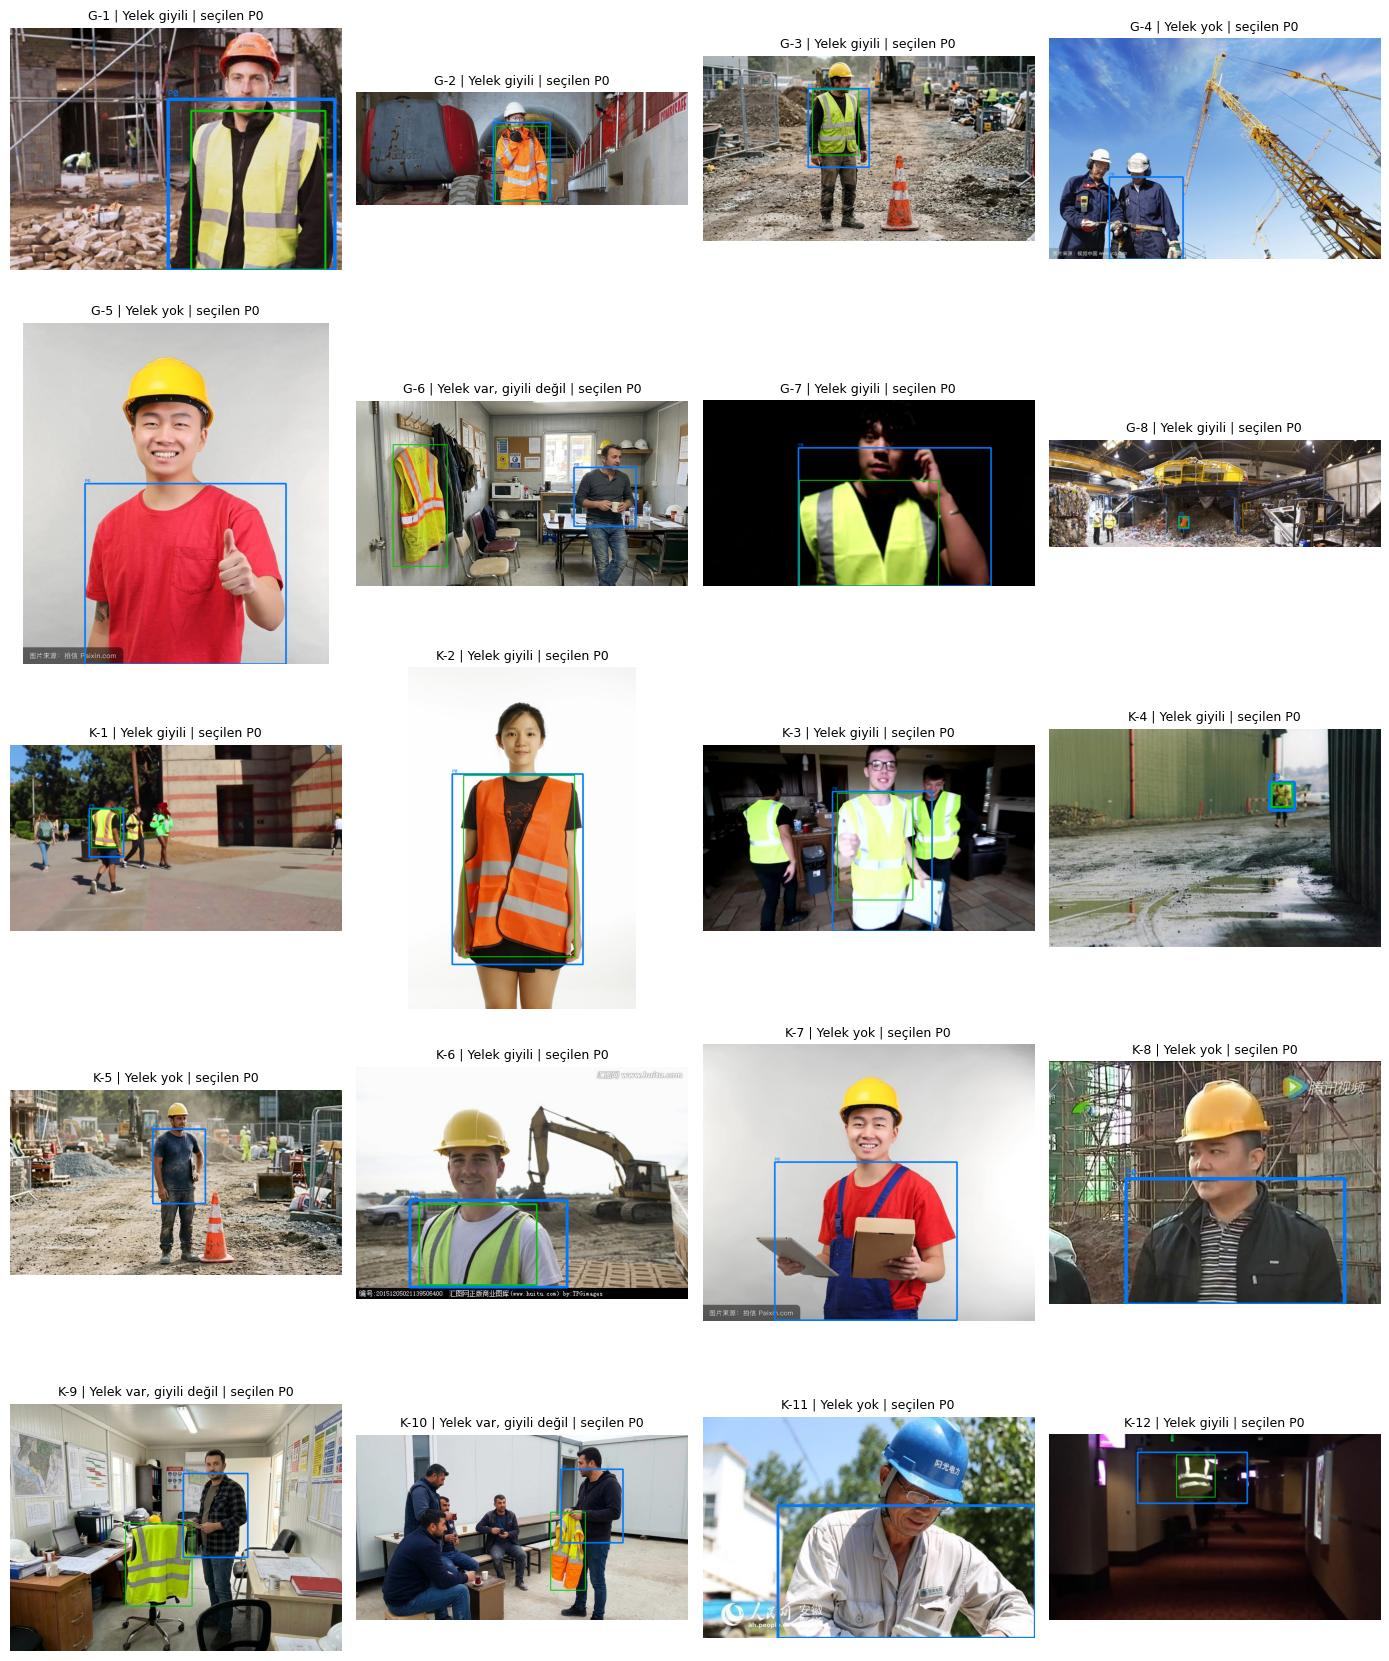

In [28]:
# Her görüntüde kutuları gözle kontrol (3c: "her görüntüde gözle kontrol edin")
E = entries(gt)
ids = DEV_IDS + CTRL_IDS
show([draw_boxes(load_img(i), E[i]) for i in ids],
     [f"{i} | {E[i]['class']} | seçilen P{E[i]['selected']}" for i in ids], cols=4, size=3.5,
     path=RES / 'fig' / 'kutular.png');

In [29]:
# 2b koşul kapsaması (sources.csv 'kosul' sütunundan)
import pandas as pd
src = pd.read_csv(DATA / 'sources.csv', dtype=str).fillna('')
need = ['normal ışık', 'gölge', 'uzak', 'koni', 'yeleksiz', 'giyili değil']
for n in need:
    hits = src[(src.ayirim == 'kontrol') & src.kosul.str.contains(n, case=False)].id.tolist()
    print(f'{n:14s}', hits if hits else 'EKSİK')
print(pd.Series({i: E[i]['class'] for i in ids}).groupby(lambda i: i[0]).value_counts())

normal ışık    ['K-1', 'K-2']
gölge          ['K-3']
uzak           ['K-4']
koni           ['K-5']
yeleksiz       ['K-5', 'K-7', 'K-8', 'K-9', 'K-11']
giyili değil   ['K-9', 'K-10']
G  Yelek giyili               5
   Yelek yok                  2
   Yelek var, giyili değil    1
K  Yelek giyili               6
   Yelek yok                  4
   Yelek var, giyili değil    2
Name: count, dtype: int64


## Dondurma 1
`gt.json/_meta` (seçim kuralı, `tpfpfn_ids` — 5f, altı görüntü, yöntemler çalışmadan önce), her görüntünün `serit` alanı (3b)
ve `sources.csv` doldurulduktan sonra kayıt alınır.

In [30]:
# kayit_al('data/gt.json', 'data/sources.csv', etiket='dondurma-1')     # <- hazır olunca yorumu kaldırıp BİR KEZ çalıştırın

## D1 — Küçültme oranı (Dondurma 2'den sonra)
Ölçü: gövde maske oranı ve gövdedeki Canny oranı. Ek: 0,125'e küçültüp geri büyütmek şeridi geri getirir mi (S5)?
Piksel cinsinden eşikler (gövde ≥ 40 px) sabit kaldığı için küçük oranlarda "Belirsiz" görmeniz beklenir; bunu yorumda yazın.

yontem 0.125→1 geri büyütme (LINEAR) INTER_AREA                       \
oran                           1.000      0.125  0.250  0.500  1.000   
id                                                                     
K-1                            0.403      0.210  0.345  0.356  0.367   
K-10                           0.133      0.115  0.123  0.124  0.125   
K-11                           0.040      0.040  0.038  0.041  0.045   
K-12                           0.000      0.000  0.000  0.000  0.000   
K-2                            0.527      0.544  0.520  0.511  0.509   
K-3                            0.058      0.055  0.058  0.065  0.068   
K-4                            0.376      0.000  0.444  0.421  0.356   
K-5                            0.062      0.007  0.086  0.083  0.086   
K-6                            0.144      0.086  0.152  0.193  0.196   
K-7                            0.291      0.300  0.300  0.296  0.297   
K-8                            0.014      0.000  0.011  0.016  0.017   
K-9                            0.024      0.011  0.016  0.022  0.025   

yontem INTER_NEAREST  
oran           0.250  
id                    
K-1            0.283  
K-10           0.119  
K-11           0.043  
K-12           0.000  
K-2            0.523  
K-3            0.054  
K-4            0.400  
K-5            0.089  
K-6            0.169  
K-7            0.300  
K-8            0.015  
K-9            0.017

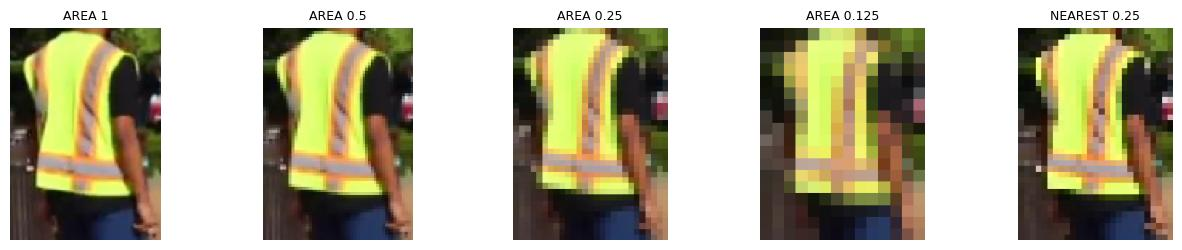

In [31]:
import experiments
P = load_params()
d1 = experiments.d1(CTRL_IDS, gt, P, kisi='A', show_id='K-1')   # show_id: slayt görseli için bir görüntü
d1.pivot_table(index='id', columns=['yontem', 'oran'], values='govde_maske_orani').round(3)

yontem 0.125→1 geri büyütme (LINEAR) INTER_AREA                       \
oran                           1.000      0.125  0.250  0.500  1.000   
id                                                                     
G-1                            0.081      0.041  0.071  0.088  0.097   
G-2                            0.557      0.689  0.554  0.527  0.518   
G-3                            0.264      0.324  0.250  0.272  0.274   
G-4                            0.002      0.000  0.000  0.002  0.002   
G-5                            0.682      0.681  0.684  0.680  0.681   
G-6                            0.000      0.000  0.000  0.000  0.001   
G-7                            0.343      0.325  0.338  0.340  0.342   
G-8                            0.590      0.000  0.375  0.434  0.479   

yontem INTER_NEAREST  
oran           0.250  
id                    
G-1            0.074  
G-2            0.535  
G-3            0.262  
G-4            0.000  
G-5            0.682  
G-6            0.000  
G-7            0.338  
G-8            0.344

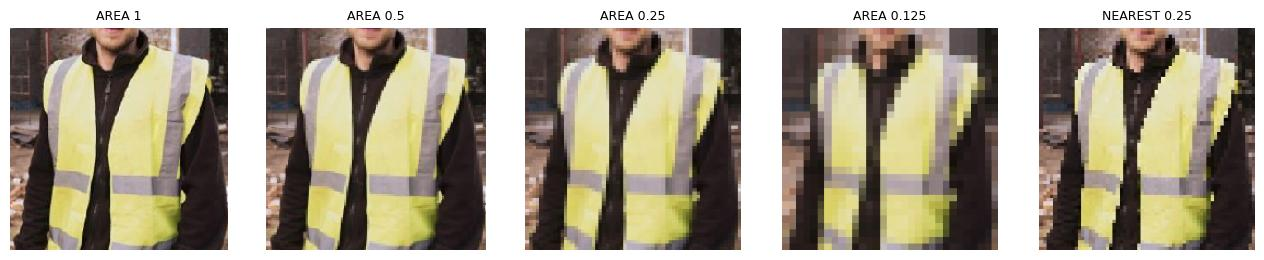

In [32]:
import experiments
P = load_params()
d1 = experiments.d1(DEV_IDS, gt, P, kisi='A', show_id='G-1')   # dondurmadan önce: yalnız geliştirme görüntüleri
d1.pivot_table(index='id', columns=['yontem', 'oran'], values='govde_maske_orani').round(3)

In [33]:
d1.pivot_table(index='id', columns=['yontem', 'oran'], values='canny_orani').round(3)

yontem 0.125→1 geri büyütme (LINEAR) INTER_AREA                       \
oran                           1.000      0.125  0.250  0.500  1.000   
id                                                                     
G-1                            0.020      0.272  0.193  0.138  0.091   
G-2                            0.000      0.329  0.309  0.256  0.215   
G-3                            0.015      0.317  0.286  0.270  0.215   
G-4                            0.013      0.277  0.263  0.216  0.155   
G-5                            0.000      0.121  0.072  0.041  0.022   
G-6                            0.007      0.318  0.220  0.214  0.178   
G-7                            0.005      0.176  0.102  0.048  0.020   
G-8                            0.000      0.562  0.359  0.264  0.239   

yontem INTER_NEAREST  
oran           0.250  
id                    
G-1            0.211  
G-2            0.330  
G-3            0.312  
G-4            0.257  
G-5            0.083  
G-6            0.268  
G-7            0.105  
G-8            0.391

## 9 — Hata incelemesi (B'nin dondurulmuş sonuçları üzerinde)
Bir yanlış alarm (FP) ve bir kaçırma (FN) seçin. Sonraki kontrol, dondurulmuş sonucun yerine yazılmaz.

In [34]:
import pandas as pd
kolon = ['id', 'dogru_sinif', 'kural_sinifi', 'govde_maske_orani', 'tp', 'fp', 'fn', 'gerekce']
if (RES / 'color.csv').exists():
    col = pd.read_csv(RES / 'color.csv')
    print("B'nin kontrol sonuçları (color.csv):")
elif (RES / 'color_dev.csv').exists():
    col = pd.read_csv(RES / 'color_dev.csv')
    print("UYARI: color.csv henüz yok; deneme için B'nin GELİŞTİRME sonuçları gösteriliyor. "
          "Asıl hata incelemesi B dondurup kontrol görüntülerini çalıştırınca yapılır.")
else:
    col = None
    print("Henüz renk sonucu yok. Önce B_renk.ipynb çalıştırılmalı "
          "(geliştirme için 'color.run(DEV_IDS…)' hücresi, kontrol için dondurmadan sonra '5c–5g' hücresi).")
if col is not None:
    display(col[(col.fp > 0) | (col.fn > 0) | (~col.dogru_mu)][kolon])

B'nin kontrol sonuçları (color.csv):


,id,dogru_sinif,kural_sinifi,govde_maske_orani,tp,fp,fn,gerekce
0,K-1,Yelek giyili,Yelek giyili,0.366975,1,15,0,ii: gövde maske oranı 0.367 >= 0.15
1,K-2,Yelek giyili,Yelek giyili,0.508691,1,5,0,ii: gövde maske oranı 0.509 >= 0.15
2,K-3,Yelek giyili,Yelek yok,0.067609,0,10,1,iv: hiçbiri
4,K-5,Yelek yok,Yelek yok,0.085935,0,13,0,iv: hiçbiri
5,K-6,Yelek giyili,Yelek giyili,0.196151,0,7,1,ii: gövde maske oranı 0.196 >= 0.15
6,K-7,Yelek yok,Yelek giyili,0.296814,0,8,0,ii: gövde maske oranı 0.297 >= 0.15
7,K-8,Yelek yok,Yelek yok,0.017353,0,3,0,iv: hiçbiri
8,K-9,"Yelek var, giyili değil","Yelek var, giyili değil",0.024602,0,10,1,iii: gövdesiz en büyük parça 11542px > 0.2×51541
9,K-10,"Yelek var, giyili değil",Yelek yok,0.124612,1,9,0,iv: hiçbiri
10,K-11,Yelek yok,Yelek yok,0.044624,0,11,0,iv: hiçbiri


In [35]:
# Sonraki kontrol örneği (yalnız ayrı satır olarak eklenir):
# import merge
# merge.add_followup('K-5', 'A', 'ne değişti: ...', kuralin_sinifi='...', govde_orani='...', serit='...', tpfpfn='...', yorum='...')

In [36]:
import json, glob
eski = ["%reload_ext autoreload\n", "%autoreload 2\n"]
yeni = ["try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir\n",
        "    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')\n",
        "except Exception:\n",
        "    pass\n"]
for f in sorted(glob.glob('notebooks/*.ipynb')) + ['main.ipynb']:
    with open(f, encoding='utf-8') as fh:
        nb = json.load(fh)
    hucre = next(c for c in nb['cells'] if c['cell_type'] == 'code')        # ilk kod hücresi = kurulum
    src = hucre['source'] if isinstance(hucre['source'], list) else hucre['source'].splitlines(keepends=True)
    if src[:0] == [] and all(s in src for s in eski):
        i = src.index(eski[0])
        hucre['source'] = src[:i] + yeni + src[i + 2:]
        with open(f, 'w', encoding='utf-8') as fh:
            json.dump(nb, fh, ensure_ascii=False, indent=1)
        print('düzeltildi:', f)
    else:
        print('zaten düzgün:', f)

zaten düzgün: notebooks/A_veri_ve_etiket.ipynb
zaten düzgün: notebooks/B_renk.ipynb
zaten düzgün: notebooks/C_kenar_sablon.ipynb
zaten düzgün: notebooks/D_oznitelik.ipynb
zaten düzgün: notebooks/E_D8_difuzyon.ipynb
zaten düzgün: main.ipynb
